In [1]:
import torch
import librosa
import scipy
import numpy as np
import matplotlib.pyplot as plt

In [2]:
print("PyTorch:",torch.__version__)
print("Librosa:",librosa.__version__)
print("Scipy:",scipy.__version__)
print("GPU availability:",torch.cuda.is_available())

PyTorch: 2.11.0+cu130
Librosa: 0.11.0
Scipy: 1.16.3
GPU availability: True


In [3]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
import os
import zipfile

source="/content/drive/MyDrive"

destination="/content/data"
os.makedirs(destination,exist_ok=True)

zip_files=[
    "clean_trainset_28spk_wav.zip",
    "noisy_trainset_28spk_wav.zip",
    "clean_testset_wav.zip",
    "noisy_testset_wav.zip"
]

for filename in zip_files:
  zip_path=os.path.join(source,filename)

  if not os.path.exists(zip_path):
    print(f"File not found:{filename}")
    continue

  print(f"Extracting:{filename}....")
  with zipfile.ZipFile(zip_path,"r") as archieve:
    archieve.extractall(destination)

  print(f"finished:{filename}")

print("Extraction complete")

Extracting:clean_trainset_28spk_wav.zip....
finished:clean_trainset_28spk_wav.zip
Extracting:noisy_trainset_28spk_wav.zip....
finished:noisy_trainset_28spk_wav.zip
Extracting:clean_testset_wav.zip....
finished:clean_testset_wav.zip
Extracting:noisy_testset_wav.zip....
finished:noisy_testset_wav.zip
Extraction complete


In [6]:
import os
for root ,dirs,files in os.walk("/content/data"):
  wav_files=[f for f in files if f.endswith(".wav")]

  if wav_files:
    print(root)
    print("Number of WAV Files:",len(wav_files))
    print("Examples:",wav_files[:5])
    print()

/content/data/noisy_trainset_28spk_wav
Number of WAV Files: 11572
Examples: ['p277_053.wav', 'p231_363.wav', 'p273_234.wav', 'p227_181.wav', 'p227_266.wav']

/content/data/clean_testset_wav
Number of WAV Files: 824
Examples: ['p232_039.wav', 'p232_297.wav', 'p232_389.wav', 'p232_324.wav', 'p257_288.wav']

/content/data/clean_trainset_28spk_wav
Number of WAV Files: 11572
Examples: ['p277_053.wav', 'p231_363.wav', 'p273_234.wav', 'p227_181.wav', 'p227_266.wav']

/content/data/noisy_testset_wav
Number of WAV Files: 824
Examples: ['p232_039.wav', 'p232_297.wav', 'p232_389.wav', 'p232_324.wav', 'p257_288.wav']



In [7]:
import os

for folder in os.listdir("/content/data"):
  path=os.path.join("/content/data",folder)

  if os.path.isdir(path):
    files=[f for f in os.listdir(path) if f.endswith(".wav")]
    print(folder,"->",len(files),"WAV files")

noisy_trainset_28spk_wav -> 11572 WAV files
clean_testset_wav -> 824 WAV files
clean_trainset_28spk_wav -> 11572 WAV files
noisy_testset_wav -> 824 WAV files


In [8]:
from IPython.display import Audio,display
#this is used to display audio files like it creates a audio player

clean_dir="/content/data/clean_trainset_28spk_wav"
noisy_dir="/content/data/noisy_trainset_28spk_wav"


filename="p239_371.wav"

clean,sr=librosa.load(
    os.path.join(clean_dir,filename),
    sr=None,mono=True
)
#librosa.load() reads the audio file and converts its audio samples into numpy array


noisy,_=librosa.load(
    os.path.join(noisy_dir,filename),
    sr=None,mono=True
)

print("samplee rate:",sr)
print("Clean duration:",len(clean)/sr,"seconds")
print("Noisy duration:",len(noisy)/sr,"seconds")

print("Clean Audio:")
display(Audio(clean,rate=sr))
print("Noisy speech:")
display(Audio(noisy,rate=sr))

samplee rate: 48000
Clean duration: 2.44 seconds
Noisy duration: 2.44 seconds
Clean Audio:


Noisy speech:


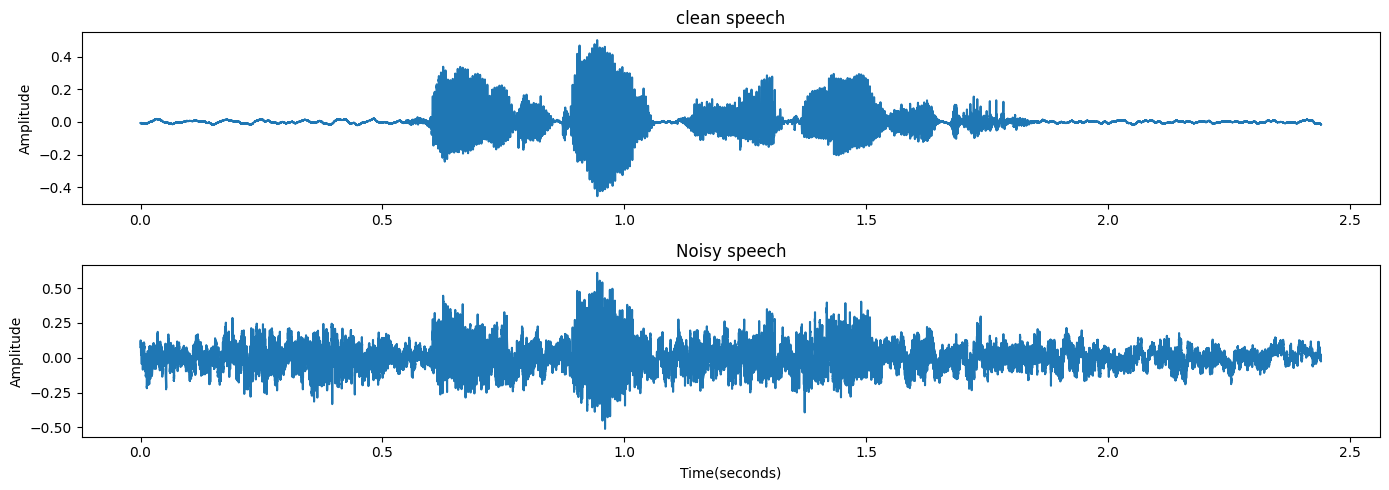

In [9]:
plt.figure(figsize=(14,5))
plt.subplot(2,1,1)
plt.plot(np.arange(len(clean))/sr,clean)
plt.title("clean speech")
plt.ylabel("Amplitude")

plt.subplot(2,1,2)
plt.plot(np.arange(len(noisy))/sr,noisy)
plt.title("Noisy speech")
plt.ylabel("Amplitude")
plt.xlabel("Time(seconds)")

plt.tight_layout()
plt.show()

## Applying STFT

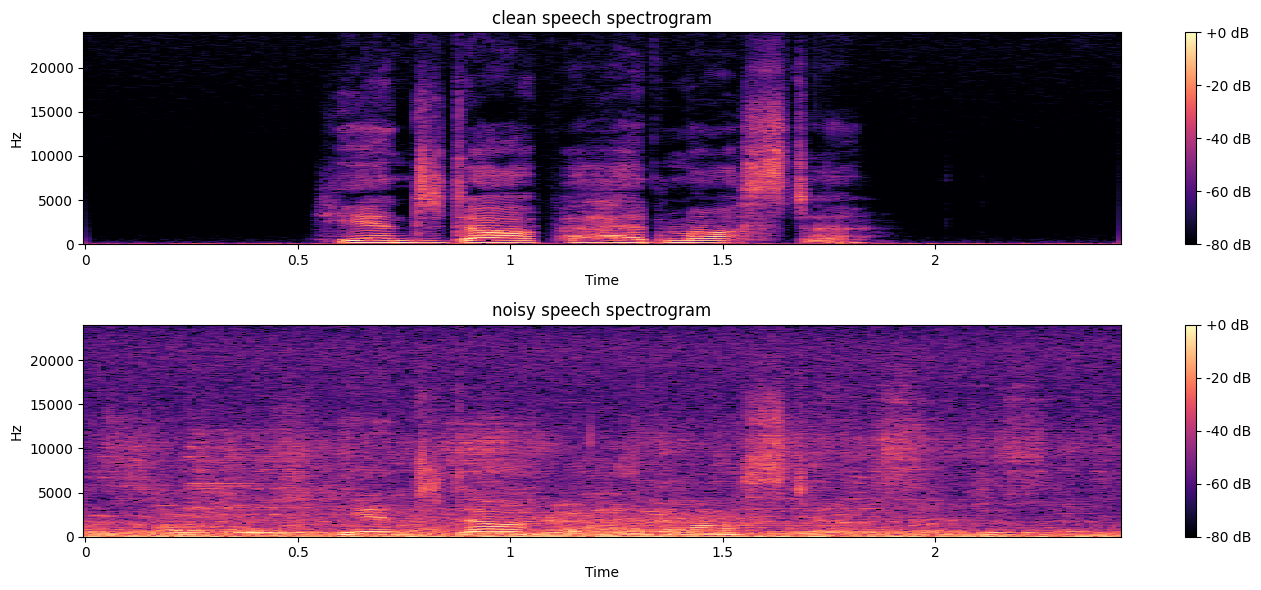

In [10]:
#converting audio into freq domain
clean_stft=librosa.stft(clean)
noisy_stft=librosa.stft(noisy)

#making amplitude in decibles
clean_db=librosa.amplitude_to_db(abs(clean_stft),ref=np.max)
noisy_db=librosa.amplitude_to_db(abs(noisy_stft),ref=np.max)
#abs()-extracts the magnitude of each frequency



plt.figure(figsize=(14,6))

plt.subplot(2,1,1)
librosa.display.specshow(
    clean_db,sr=sr,x_axis="time",y_axis="hz"
)
#specshow()-displays freq strength across time
plt.title("clean speech spectrogram")
plt.colorbar(format="%+2.0f dB")

plt.subplot(2,1,2)
librosa.display.specshow(
    noisy_db,sr=sr,x_axis="time",y_axis="hz"
)
plt.title("noisy speech spectrogram")
plt.colorbar(format="%+2.0f dB")

plt.tight_layout() #makes sures the spacing btw everything is right in a tight space
plt.show()

In [11]:
noisy_mag=np.abs(noisy_stft)
noisy_angle=np.angle(noisy_stft)

print("original shape:",noisy.shape)
print("STFT shape:",noisy_stft.shape)
print("Magnitude shape:",noisy_mag.shape)
print("Phase shape:",noisy_angle.shape)

original shape: (117120,)
STFT shape: (1025, 229)
Magnitude shape: (1025, 229)
Phase shape: (1025, 229)


In [12]:
clean_mag=np.abs(clean_stft)

## Creating Target mask for noisy audio

target mask estimates how much of each noisy component should be retained(not removed)


In [13]:
import numpy as np
eps=1e-8

target_mask=np.clip(
    clean_mag/(noisy_mag+eps),0,1
)
#np.clip()-restricst the mask value from 0 to 1 by making every value below 0 with 0 and any value above 1 with 1

print("Clean Magnitude:",clean_mag.shape)
print("Noisy magnitude:",noisy_mag.shape)
print("Target mask:",target_mask.shape)
print("Mask range:",target_mask.min(),"to",target_mask.max())

Clean Magnitude: (1025, 229)
Noisy magnitude: (1025, 229)
Target mask: (1025, 229)
Mask range: 1.7201462e-05 to 1.0


In [14]:
import os
import torch
from torch.utils.data import Dataset,DataLoader

sample_rate=16000
n_fft=512
hop_length=128
segment_length=sample_rate
eps=1e-8


## Creating Dataset

In [15]:
class SpeechDataset(Dataset):
  def __init__(self,clean_dir,noisy_dir):
    self.clean_dir=clean_dir
    self.noisy_dir=noisy_dir

    clean_files=set(os.listdir(clean_dir))
    noisy_files=set(os.listdir(noisy_dir))

    self.files=sorted(
        f for f in clean_files & noisy_files
        if f.endswith(".wav")
    )

    print("Matched audio pairs:",len(self.files))

  def __len__(self):
    return len(self.files)

  def __getitem__(self,idx):
    filename=self.files[idx]

    clean,_=librosa.load(
        os.path.join(self.clean_dir,filename),
        sr=sample_rate,mono=True
    )
    noisy,_=librosa.load(
        os.path.join(self.noisy_dir,filename),
        sr=sample_rate,mono=True
    )

    start=np.random.randint(
        0,max(1,len(clean)-segment_length+1)
    )

    clean=clean[start:start+segment_length]
    noisy=noisy[start:start+segment_length]

    clean=np.pad(clean,(0,segment_length-len(clean)))
    noisy=np.pad(noisy,(0,segment_length-len(noisy)))

    clean_stft=librosa.stft(clean,n_fft=n_fft,hop_length=hop_length)
    noisy_stft=librosa.stft(noisy,n_fft=n_fft,hop_length=hop_length)

    clean_mag=np.abs(clean_stft)
    noisy_mag=np.abs(noisy_stft)

    mask=np.clip(
        clean_mag/(noisy_mag+eps),0,1
    )

    return (
        torch.tensor(noisy_mag,dtype=torch.float32),
        torch.tensor(mask,dtype=torch.float32)
    )

## Creating the dataset


In [16]:
clean_train_dir="/content/data/clean_trainset_28spk_wav"
noisy_train_dir="/content/data/noisy_trainset_28spk_wav"

train_dataset=SpeechDataset(clean_train_dir,noisy_train_dir)

Matched audio pairs: 11572


### Testing


In [17]:
noisy_mag,target_mask=train_dataset[0]

print("Noisy mag:",noisy_mag.shape)
print("Target mask:",target_mask.shape)

print("noisy dtype",noisy_mag.dtype)
print("mask dtype",target_mask.dtype)
print("mask minimum:",target_mask.min().item())
print("mask maximum:",target_mask.max().item())

Noisy mag: torch.Size([257, 126])
Target mask: torch.Size([257, 126])
noisy dtype torch.float32
mask dtype torch.float32
mask minimum: 0.00013804386253468692
mask maximum: 1.0


## DAtaLoader


In [18]:
from torch.utils.data import DataLoader
train_loader=DataLoader(
    train_dataset,batch_size=32,
    shuffle=True,
    num_workers=2
)

## Testing the dataloader

In [19]:
noisy_batch,mask_batch=next(iter(train_loader))

print("noisy_batch_shape:",noisy_batch.shape)
print("mask_batch_shape:",mask_batch.shape)

noisy_batch_shape: torch.Size([32, 257, 126])
mask_batch_shape: torch.Size([32, 257, 126])


# Making the CNN model

In [20]:
import torch
import torch.nn as nn

class SpeechEnhancementCNN(nn.Module):
  def __init__(self):
    super().__init__()

    self.network =nn.Sequential(
        nn.Conv2d(1,16,kernel_size=3,padding=1),
        nn.ReLU(),
        nn.Conv2d(16,32,kernel_size=3,padding=1),
        nn.ReLU(),
        nn.Conv2d(32,16,kernel_size=3,padding=1),
        nn.ReLU(),
        nn.Conv2d(16,1,kernel_size=3,padding=1),
        nn.Sigmoid(),
    )
  def forward(self,x):
    return self.network(x)

## Intializing the model

In [21]:
#checking device
device=torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model=SpeechEnhancementCNN().to(device)

print(device)
print(model)

cuda
SpeechEnhancementCNN(
  (network): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU()
    (6): Conv2d(16, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): Sigmoid()
  )
)


### Testing model with one batch

In [22]:
noisy_batch,mask_batch=next(iter(train_loader))
noisy_batch=noisy_batch.unsqueeze(1).to(device)

predicted_mask=model(noisy_batch)

print("Input shape:",noisy_batch.shape)
print("Predicted mask shape:",predicted_mask.shape)
print("Target Maks shape:",mask_batch.shape)

Input shape: torch.Size([32, 1, 257, 126])
Predicted mask shape: torch.Size([32, 1, 257, 126])
Target Maks shape: torch.Size([32, 257, 126])


## optimizer and loss fn


In [23]:
import torch.optim as optim
criterion=nn.MSELoss()
optimizer=optim.Adam(
    model.parameters(),
    lr=0.001
)

## TEsting loss calculation

In [24]:
noisy_batch,mask_batch=next(iter(train_loader))

noisy_batch=noisy_batch.unsqueeze(1).to(device)
mask_batch=mask_batch.unsqueeze(1).to(device)

predicted_mask=model(noisy_batch)

loss=criterion(predicted_mask,mask_batch)

print("Loss:",loss.item())

Loss: 0.15978480875492096


## Training the neural network

In [25]:
num_epochs=10

for epoch in range(num_epochs):
  model.train()
  running_loss=0

  for noisy_batch,mask_batch in train_loader:
    noisy_batch=noisy_batch.unsqueeze(1).to(device)
    mask_batch=mask_batch.unsqueeze(1).to(device)

    optimizer.zero_grad()

    predicted_mask=model(noisy_batch)

    loss=criterion(predicted_mask,mask_batch)

    loss.backward()
    optimizer.step()

    running_loss+=loss.item()

  epoch_loss=running_loss/len(train_loader)
  print(f"Epoch [{epoch+1}/num{num_epochs}],Loss:{epoch_loss:.4f}")

Epoch [1/num10],Loss:0.1442
Epoch [2/num10],Loss:0.1299
Epoch [3/num10],Loss:0.1264
Epoch [4/num10],Loss:0.1243
Epoch [5/num10],Loss:0.1228
Epoch [6/num10],Loss:0.1220
Epoch [7/num10],Loss:0.1208
Epoch [8/num10],Loss:0.1202
Epoch [9/num10],Loss:0.1193
Epoch [10/num10],Loss:0.1184


## Testing the model


In [26]:
import os
import torch
from IPython.display import Audio,display

clean_test_dir="/content/data/clean_testset_wav"
noisy_test_dir="/content/data/noisy_testset_wav"

filename=sorted(os.listdir(noisy_test_dir))[0]



noisy,sr=librosa.load(
    os.path.join(noisy_test_dir,filename),
    sr=sample_rate,
    mono=True
)

print("Filename:",filename)
print("Duration:",len(noisy)/sr,"seconds")

display(Audio(noisy,rate=sr))

Filename: p232_001.wav
Duration: 1.7413125 seconds


In [27]:
model.eval()

noisy_stft=librosa.stft(noisy,n_fft=n_fft,hop_length=hop_length)
noisy_mag=np.abs(noisy_stft)
noisy_tensor=torch.tensor(
    noisy_mag,
    dtype=torch.float32
).unsqueeze(0).unsqueeze(0).to(device)

with torch.no_grad():
  predicted_mask=model(noisy_tensor)

predicted_mask=predicted_mask.squeeze().cpu().numpy()
enhanced_mag=noisy_mag*predicted_mask

enhanced_stft=enhanced_mag*np.exp(1j*np.angle(noisy_stft))
enhanced_audio=librosa.istft(
    enhanced_stft,
    hop_length=hop_length,
    length=len(noisy)
)

display(Audio(enhanced_audio,rate=sr))

## conparing noisy with enhanced audio

In [28]:
!pip install pesq pystoi

#idk what it is chatgpt told me to use it

  Preparing metadata (setup.py) ... done
  Created wheel for pesq: filename=pesq-0.0.4-cp313-cp313-linux_x86_64.whl size=279146 sha256=8fa33ccbb1de2f1f8eedcd0c50dccb4aab62470d6266008f9c69903836c06351
  Stored in directory: /root/.cache/pip/wheels/7f/fd/bd/0db325a6b4eee46eb45834f881c452d8b651e8ee8dc86546f9
Successfully built pesq


pesq- measures the speech quality


stoi- measures the speech understandability

In [29]:
from pesq import pesq
from pystoi import stoi


#loading the clean version of the audio
clean,_=librosa.load(
    os.path.join(clean_test_dir,filename),
    sr=sample_rate,
    mono=True
)


#Finds the length of the shortest recording for all three audios
min_len=min(len(clean),len(noisy),len(enhanced_audio))


#cutting all recordings to same length
clean_eval=clean[:min_len]
noisy_eval=noisy[:min_len]
enhanced_eval=enhanced_audio[:min_len]

#compares noisy with clean reference
pesq_score=pesq(sr,clean_eval,noisy_eval,mode="wb")

#compares the enhanced audio with the clean reference
pesq_enhanced=pesq(sr,clean_eval,enhanced_eval,mode="wb")

#understandability of noisy
stoi_noisy=stoi(clean_eval,noisy_eval,sr)
#understandility of the enhanced
stoi_enhanced=stoi(clean_eval,enhanced_eval,sr)

print("Noisy pesq and Enhanced pesq",pesq_score,"and",pesq_enhanced)
print("noisy stoi and enhanced stoi",stoi_noisy,"and",stoi_enhanced)

Noisy pesq and Enhanced pesq 2.924609899520874 and 2.9874329566955566
noisy stoi and enhanced stoi 0.8965751637447984 and 0.8867962589548922


### Evaluating the entire testset

In [31]:
from pesq import pesq
from pystoi import stoi
from tqdm.auto import tqdm
import os
import numpy as np
import librosa
import torch

model.eval()

#sorting the clean and noisy audios for them to match and putting them together
test_files=sorted(
    set(os.listdir(clean_test_dir)) &
    set(os.listdir(noisy_test_dir))
)

#list of score
noisy_pesq_scores=[]
enhanced_pesq_scores=[]
noisy_stoi_scores=[]
enhanced_stoi_scores=[]

failed_files=[]

for filename in tqdm(test_files):
  try:
    clean,_=librosa.load(
        os.path.join(clean_test_dir,filename),
        sr=sample_rate, mono=True
    )

    noisy,_=librosa.load(
        os.path.join(noisy_test_dir,filename),
        sr=sample_rate,mono=True
    )

    #using same length for comparision
    noisy_stft=librosa.stft(
        noisy,n_fft=n_fft,hop_length=hop_length
    )
    noisy_mag=np.abs(noisy_stft)

    #converting the spectrogram into a tensor
    noisy_tensor=torch.tensor(
        noisy_mag,dtype=torch.float32
    ).unsqueeze(0).unsqueeze(0).to(device)

    with torch.no_grad():
      predicted_mask=model(noisy_tensor)


    #converting the predicted mask back to numpy
    predicted_mask=predicted_mask[0,0].cpu().numpy()

    #apply mask
    enhanced_mag=noisy_mag*predicted_mask
    enhanced_stft=enhanced_mag*np.exp(
        1j*np.angle(noisy_stft)
    )
    enhanced_audio=librosa.istft(
        enhanced_stft,
        hop_length=hop_length,
        length=len(noisy)
    )

    noisy_pesq=pesq(
        sample_rate,clean,noisy,mode="wb"
    )
    enhanced_pesq=pesq(
        sample_rate,clean,enhanced_audio,mode="wb"
    )

    noisy_stoi=stoi(
        clean,noisy,sample_rate,extended=False
    )
    enhanced_stoi=stoi(
        clean,enhanced_audio,sample_rate,extended=False
    )

    noisy_pesq_scores.append(noisy_pesq)
    enhanced_pesq_scores.append(enhanced_pesq)
    noisy_stoi_scores.append(noisy_stoi)
    enhanced_stoi_scores.append(enhanced_stoi)

  except Exception as e:
    failed_files.append((filename,str(e)))


print("\n Evaluation results:")
print("Succesfully evaluated:",len(noisy_pesq_scores))
print("Failed to evaluate:",len(failed_files))


print("\n AVg PESQ:")
print("Noisy:",np.mean(noisy_pesq_scores))
print("Enhanced pesq:",np.mean(enhanced_pesq_scores))

print("\n Avg stoi:")
print("Noisy:",np.mean(noisy_stoi_scores))
print("Enhanced:",np.mean(enhanced_stoi_scores))

  0%|          | 0/824 [00:00<?, ?it/s]


 Evaluation results:
Succesfully evaluated: 824
Failed to evaluate: 0

 AVg PESQ:
Noisy: 1.9673304634476172
Enhanced pesq: 2.423656533210023

 Avg stoi:
Noisy: 0.9210630436910627
Enhanced: 0.9059182310510039


The results look good let's save the model

## Saving the model

In [32]:
from google.colab import files

torch.save(model.state_dict(),"speech_enhancement_model.pth")

files.download("speech_enhancement_model.pth")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>